# VAE and Conditional VAE on MNIST — from scratch and with `torch.distributions`

A short notebook with three models:

1. **VAE with a Bernoulli decoder** on binarized MNIST;
2. **VAE with a Normal (Gaussian) decoder** on grayscale MNIST;
3. **Conditional VAE (CVAE)** that generates a digit of a *chosen class*;
4. **CVAE for inpainting**: given the *top half* of a digit, sample plausible *bottom halves*, compared with a plain feed-forward network.

Every probabilistic piece is written **twice, side by side**: once by hand (formulas only), and once with `torch.distributions`. A check cell confirms that the two give the same numbers. Training can use either implementation (`USE_TD` flag).

Set `FAST = True` for a quick smoke test. A full run takes a few minutes on a GPU.

## 1. Theory in one page

**Model.** $z\sim p(z)$, $x\sim p_\theta(x\mid z)$, where a neural network (the decoder) outputs the parameters of $p_\theta(x\mid z)$. Pixels are conditionally independent given $z$: $p_\theta(x\mid z)=\prod_i p_\theta(x_i\mid z)$.

**ELBO.** With an encoder $q_\phi(z\mid x)=\mathcal N(\mu_\phi(x),\operatorname{diag}\sigma^2_\phi(x))$:
$$
\log p_\theta(x)\;\ge\;\mathcal L=\mathbb E_{q_\phi(z\mid x)}\big[\log p_\theta(x\mid z)\big]-\mathrm{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big),
\qquad \log p_\theta(x)-\mathcal L=\mathrm{KL}\big(q_\phi(z\mid x)\,\|\,p_\theta(z\mid x)\big).
$$

**Reparameterization.** $z=\mu+\sigma\odot\varepsilon$ with $\varepsilon\sim\mathcal N(0,I)$ makes the sample a differentiable function of $(\mu,\sigma)$.

**KL between diagonal Gaussians** (per dimension, then summed):
$$
\mathrm{KL}\big(\mathcal N(\mu_q,\sigma_q^2)\,\|\,\mathcal N(\mu_p,\sigma_p^2)\big)=\tfrac12\Big(\log\tfrac{\sigma_p^2}{\sigma_q^2}+\tfrac{\sigma_q^2+(\mu_q-\mu_p)^2}{\sigma_p^2}-1\Big).
$$
With $p=\mathcal N(0,1)$ this becomes $\tfrac12(\mu_q^2+\sigma_q^2-1-\log\sigma_q^2)$.

**Decoder likelihoods.**
* Bernoulli with logits $\ell$ (binary pixels): $\log p(x\mid\ell)=x\ell-\operatorname{softplus}(\ell)$. This is BCE-with-logits.
* Normal with mean $\mu$ and one learned $\sigma$ (grayscale pixels): $\log p(x)=-\tfrac12\log 2\pi-\log\sigma-\tfrac{(x-\mu)^2}{2\sigma^2}$. With a *fixed* σ this is MSE up to a scale, and that scale acts as a hidden β on the KL term. Learning σ removes this hyperparameter.

**Conditional VAE** (Sohn et al., 2015). Every distribution is conditioned on $c$ (here, the one-hot digit label):
$$
\log p(x\mid c)\ \ge\ \mathbb E_{q_\phi(z\mid x,c)}\log p_\theta(x\mid z,c)-\mathrm{KL}\big(q_\phi(z\mid x,c)\,\|\,p_\psi(z\mid c)\big).
$$
The prior $p_\psi(z\mid c)$ is a third network, a Gaussian whose parameters depend on $c$. That is why we need the general Gaussian–Gaussian KL above. To generate a digit of class $c$, sample $z\sim p_\psi(z\mid c)$ and decode with $c$.

**Evaluation.** An importance-sampled estimate with the encoder as proposal:
$\log p(x)\approx\log\frac1K\sum_k \frac{p(x\mid z_k)p(z_k)}{q(z_k\mid x)}$, with $z_k\sim q(z\mid x)$. It is tighter than the ELBO and approaches $\log p(x)$ as $K\to\infty$.

In [ ]:
import math, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.datasets import MNIST
from torchvision.utils import make_grid

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
FAST =  False
EPOCHS = 2 if FAST else 20
EVAL_N, EVAL_K = (200, 50) if FAST else (2000, 500)
print(device)

cuda


## 2. Data

Images are flattened to vectors of length $D=784$ with values in $[0,1]$, and labels are one-hot vectors.
* **Bernoulli models:** training digits are re-binarized as $\text{Bernoulli}(x)$ every time they are seen (*dynamic binarization*). The test set is binarized once, with a fixed seed.
* **Normal model:** the grayscale values are used directly.

In [ ]:
tr, te = MNIST('./data', train=True, download=True), MNIST('./data', train=False, download=True)

In [ ]:
p = (tr.data[0]/255).flatten()
samp = torch.bernoulli(p)

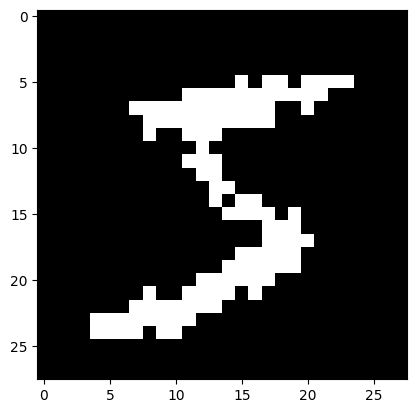

In [ ]:
plt.imshow(samp.view(28,28), cmap='gray') # , cmap='gray'

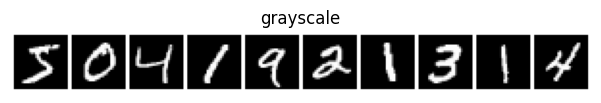

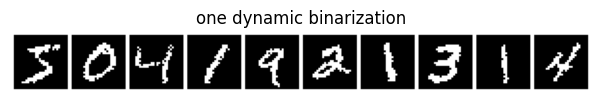

In [ ]:
x_train = (tr.data.view(-1, 784).float() / 255).to(device)
x_test  = (te.data.view(-1, 784).float() / 255).to(device)
y_train, y_test = tr.targets.to(device), te.targets.to(device)
c_train, c_test = F.one_hot(y_train, 10).float(), F.one_hot(y_test, 10).float()
g = torch.Generator(device=device).manual_seed(1)     # CPU generator
x_test_bin = torch.bernoulli(x_test, generator=g)     # depends on the x_test device
# x_test_bin = torch.bernoulli(x_test.cpu(), generator=g).to(device)

def show(x, nrow=10, title=None, scale=0.8):
    grid = make_grid(x.detach().view(-1, 1, 28, 28).cpu().clamp(0, 1), nrow=nrow, pad_value=1)
    plt.figure(figsize=(nrow * scale, math.ceil(len(x) / nrow) * scale))
    plt.imshow(grid.permute(1, 2, 0)); plt.axis('off')
    if title: plt.title(title)
    plt.show()

show(x_train[:10], title='grayscale'); show(torch.bernoulli(x_train[:10]), title='one dynamic binarization')

## 3. The probability toolbox, twice

### 3a. By hand

Five functions are all a VAE needs. Everything is summed over the last dimension (latent dims or pixels) and returns one number per example.

In [ ]:
LOG2PI = math.log(2 * math.pi)

def reparameterize(mu, logvar, K=None):
    """z = mu + sigma * eps. With K, returns (K, N, d)."""
    eps = torch.randn(mu.shape if K is None else (K, *mu.shape), device=mu.device)
    return mu + torch.exp(0.5 * logvar) * eps  # \sigma = sqrt[ exp(log \sigma^2) ]

def log_normal(x, mu, logvar):                       # sum_i log N(x_i | mu_i, exp(logvar_i))
    return (-0.5 * (LOG2PI + logvar + (x - mu) ** 2 / logvar.exp())).sum(-1)

def log_bernoulli(x, logits):                        # sum_i [x_i * l_i - softplus(l_i)]
    return (x * logits - F.softplus(logits)).sum(-1)
    # softplus(s) = max(s,0) + log(1 + exp(-|s|))

def kl_normal(mu_q, logvar_q, mu_p, logvar_p):       # KL( N(mu_q, .) || N(mu_p, .) ), summed
    return 0.5 * (logvar_p - logvar_q + (logvar_q.exp() + (mu_q - mu_p) ** 2) / logvar_p.exp() - 1).sum(-1)

def log_mean_exp(a, dim=0):                          # stable log( mean( exp(a) ) )
    m = a.max(dim, keepdim=True).values
    return (m + (a - m).exp().mean(dim, keepdim=True).log()).squeeze(dim)

### 3b. With `torch.distributions`

**What the library is.** Each distribution is a Python object built from parameter tensors (`Normal(loc, scale)`, `Bernoulli(logits=...)`). It provides:

| method / attribute | what it does | our by-hand equivalent |
|---|---|---|
| `d.rsample(shape)` | **reparameterized** sample, e.g. `loc + scale * eps` for `Normal`; gradients flow into `loc` and `scale` | `reparameterize` |
| `d.sample(shape)` | sample under `no_grad`, so gradients do not flow (the only option for discrete distributions such as `Bernoulli`) | `torch.bernoulli` |
| `d.log_prob(x)` | log-density or log-pmf of `x`, computed stably (e.g. from logits) | `log_normal`, `log_bernoulli` |
| `kl_divergence(q, p)` | **analytic** KL, looked up in a registry by the *types* of `q` and `p`; raises an error if no closed form is registered | `kl_normal` |
| `d.mean`, `d.stddev`, `d.entropy()` | moments and entropy | — |

**Shapes are the one concept to learn.**
* `batch_shape`: how many *independent, different* distributions the object holds.
* `event_shape`: the shape of *one* sample from *one* of them. `log_prob` sums over the event dimensions and returns one value per batch element.

`Normal(mu, sigma)` with `mu` of shape `(N, d)` is **N·d scalar Gaussians** (`batch_shape=(N,d)`, `event_shape=()`), so its `log_prob` returns an `(N,d)` tensor. `Independent(Normal(mu, sigma), 1)` reinterprets the last batch dim as an event dim: N diagonal Gaussians in $\mathbb R^d$, whose `log_prob` returns `(N,)`, already summed. This is exactly the `.sum(-1)` in our by-hand functions. Forgetting `Independent` is the most common bug, because the shapes then broadcast silently.

`rsample((K,))` *prepends* a sample dimension: `(K, N, d)`. `log_prob` of a `(K, N, d)` tensor under a distribution with batch shape `(N,)` broadcasts to `(K, N)`.

**Validation.** By default, `log_prob` checks that its argument lies in the support. `Bernoulli(...).log_prob(0.3)` raises an error, which catches the common mistake of using BCE on non-binary pixels.

In [ ]:
from torch.distributions import Normal, Bernoulli, Independent, kl_divergence

In [ ]:
mu, logvar = torch.randn(4, 3), torch.randn(4, 3)

In [ ]:
q = Normal(mu, torch.exp(0.5 * logvar))
q = Independent(q, 1)

In [ ]:
q.rsample((5,)).shape

torch.Size([5, 4, 3])

In [ ]:

q_flat = Normal(mu, torch.exp(0.5 * logvar))
q = Independent(q_flat, 1)
print('Normal      : batch', tuple(q_flat.batch_shape), 'event', tuple(q_flat.event_shape))
print('Independent : batch', tuple(q.batch_shape), 'event', tuple(q.event_shape))
print('rsample((5,)) shape:', tuple(q.rsample((5,)).shape), '| has_rsample:', q.has_rsample,
      '| Bernoulli has_rsample:', Bernoulli(logits=torch.zeros(1)).has_rsample)

try:
    Bernoulli(logits=torch.zeros(3)).log_prob(torch.tensor([0.3, 1.0, 0.0]))
except ValueError as e:
    print('validation caught a non-binary target:', str(e)[:90], '...')

Normal      : batch (4, 3) event ()
Independent : batch (4,) event (3,)
rsample((5,)) shape: (5, 4, 3) | has_rsample: True | Bernoulli has_rsample: False
validation caught a non-binary target: Expected value argument (Tensor of shape (3,)) to be within the support (Boolean()) of the ...


### 3c. Check that both implementations agree

In [ ]:
z = torch.randn(4, 3); x = torch.bernoulli(torch.full((4, 784), 0.3)); l = torch.randn(4, 784)
mu_p, logvar_p = torch.randn(4, 3), torch.randn(4, 3)
p = Independent(Normal(mu_p, torch.exp(0.5 * logvar_p)), 1)
x_cont, m_dec, ls = torch.rand(4, 784), torch.rand(4, 784), torch.tensor(-2.0)

checks = {
    'log N(z | q)':         (log_normal(z, mu, logvar),               q.log_prob(z)),
    'log Bernoulli(x | l)': (log_bernoulli(x, l),                      Independent(Bernoulli(logits=l), 1).log_prob(x)),
    'log N(x | m, sigma)':  (log_normal(x_cont, m_dec, 2 * ls.expand(784)), Independent(Normal(m_dec, ls.exp()), 1).log_prob(x_cont)),
    'KL(q || p)':           (kl_normal(mu, logvar, mu_p, logvar_p),   kl_divergence(q, p)),
    'KL(q || N(0,I))':      (kl_normal(mu, logvar, torch.zeros(3), torch.zeros(3)),
                             kl_divergence(q, Independent(Normal(torch.zeros(3), torch.ones(3)), 1))),
}
for k, (a, b) in checks.items():
    print(f'{k:22s} max |diff| = {(a - b).abs().max().item():.2e}')

log N(z | q)           max |diff| = 9.54e-07
log Bernoulli(x | l)   max |diff| = 6.10e-05
log N(x | m, sigma)    max |diff| = 0.00e+00
KL(q || p)             max |diff| = 9.54e-07
KL(q || N(0,I))        max |diff| = 0.00e+00


In [ ]:
a = torch.tensor(0.2, requires_grad=True)
b = a.cos()
b.backward()
a.values, a.grad, b, -np.sin(0.2)

(<function Tensor.values()>,
 tensor(-0.1987),
 tensor(0.9801, grad_fn=<CosBackward0>),
 np.float64(-0.19866933079506122))

## 1. Gradients

### 1a. Through a reparameterized sample, `rsample()`

`mu` and `log_sigma` play the role of encoder outputs. We create them as **leaf tensors** with `requires_grad=True`. Leaves are the tensors in which PyTorch **stores** gradients (in `.grad`) after `.backward()`.

`rsample()` computes $z=\mu+\sigma\varepsilon$ with $\varepsilon\sim\mathcal N(0,1)$ drawn *outside* the graph, so $z$ is a differentiable function of $\mu$ and $\sigma$:
$$\frac{\partial z}{\partial\mu}=1,\qquad \frac{\partial z}{\partial\log\sigma}=\sigma\varepsilon .$$
For the toy loss $L=\sum z^2$: $\;\partial L/\partial\mu = 2z$ and $\partial L/\partial\log\sigma = 2z\,\sigma\varepsilon$.

In [ ]:
mu = torch.tensor([0.5, -1.0], requires_grad=True)          # leaf tensors ("parameters")
log_sigma = torch.tensor([0.0, -0.5], requires_grad=True)
q = Normal(mu, log_sigma.exp())

z = q.rsample()                                  # z = mu + sigma * eps  -> part of the autograd graph
print('z            :', z)
print('z.grad_fn    :', z.grad_fn)               # the op that created z; backward goes through it
print('is z a leaf? :', z.is_leaf)

loss = (z ** 2).sum()
loss.backward()                                  # computes dL/d(leaf) for every leaf in the graph ...

print('\nstored gradients (in .grad of the leaves):')    # ... and STORES them here
print('mu.grad        =', mu.grad)
print('log_sigma.grad =', log_sigma.grad)

# check against the formulas above
with torch.no_grad():
    sigma = log_sigma.exp()
    eps = (z - mu) / sigma
    print('\nanalytic 2z          =', 2 * z)
    print('analytic 2z*sigma*eps =', 2 * z * sigma * eps)

z            : tensor([-0.4365, -1.6298], grad_fn=<AddBackward0>)
z.grad_fn    : <AddBackward0 object at 0x7b97881116c0>
is z a leaf? : False

stored gradients (in .grad of the leaves):
mu.grad        = tensor([-0.8729, -3.2597])
log_sigma.grad = tensor([0.8175, 2.0531])

analytic 2z          = tensor([-0.8729, -3.2597])
analytic 2z*sigma*eps = tensor([0.8175, 2.0531])


**Where gradients are *not* stored.** $z$ is an intermediate (non-leaf) tensor, so `z.grad` stays `None`, and PyTorch prints a warning if you read it. If you want to inspect it, call `z.retain_grad()` *before* `backward()`.

**Gradients accumulate.** A second `backward()` **adds** to `.grad`. That is why training loops call `optimizer.zero_grad()` before each step.

In [ ]:
q = Normal(mu, log_sigma.exp())                  # rebuild: the first backward() freed the old graph
z = q.rsample()
z.retain_grad()                                  # ask autograd to keep the gradient of this non-leaf
(z ** 2).sum().backward()
print('z.grad (retained) =', z.grad, '  (= 2z =', (2 * z).detach(), ')')
print('mu.grad now       =', mu.grad, '  <- accumulated: first backward + this one')

mu.grad = None; log_sigma.grad = None            # what optimizer.zero_grad() does

z.grad (retained) = tensor([ 0.3343, -1.4420])   (= 2z = tensor([ 0.3343, -1.4420]) )
mu.grad now       = tensor([-0.5387, -4.7017])   <- accumulated: first backward + this one


## 4. One model class for VAE and CVAE

* `cond_dim = 0` gives a plain VAE with prior $\mathcal N(0,I)$.
* `cond_dim > 0` gives a CVAE: the encoder sees $[x, c]$, the decoder sees $[z, c]$, and a small prior network outputs $(\mu_\psi(c), \log\sigma^2_\psi(c))$.
* `likelihood` is `'bernoulli'` (the decoder outputs logits) or `'normal'` (the decoder outputs $\mu$ through a sigmoid; $\sigma$ is one learned scalar).

The class exposes the same ELBO twice: `elbo_scratch` (Section 3a functions) and `elbo_td` (distribution objects). The `td` version has three small helpers that return **distribution objects**: `q(x, c)`, `prior(c)`, `p_x(z, c)`. Once you have those objects, the ELBO and the importance-weighted bound are one line each.

In [ ]:
def mlp(i, h, o):
    return nn.Sequential(nn.Linear(i, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, o))

class CVAE(nn.Module):
    def __init__(self, latent_dim=16, likelihood='bernoulli', cond_dim=0, hidden=512, D=784):
        super().__init__()
        self.d, self.lik, self.cond_dim = latent_dim, likelihood, cond_dim
        self.enc = mlp(D + cond_dim, hidden, 2 * latent_dim)
        self.dec = mlp(latent_dim + cond_dim, hidden, D)
        self.prior_net = mlp(cond_dim, 128, 2 * latent_dim) if cond_dim else None
        if likelihood == 'normal':
            self.log_sigma = nn.Parameter(torch.tensor(math.log(0.1)))

    # ---- networks -> raw parameters (shared by both implementations)
    def _cat(self, a, c):                   # append c, broadcasting it over any leading sample dim
        return a if c is None else torch.cat([a, c.expand(*a.shape[:-1], c.shape[-1])], -1)

    def enc_params(self, x, c=None):
        return self.enc(self._cat(x, c)).chunk(2, -1)            # mu_q, logvar_q

    def prior_params(self, c, like):
        if self.prior_net is None:
            return torch.zeros_like(like), torch.zeros_like(like)
        return self.prior_net(c).chunk(2, -1)                    # mu_p, logvar_p

    def dec_out(self, z, c=None):
        return self.dec(self._cat(z, c))                         # logits, or pre-sigmoid mean

    # ---- (a) by hand
    def log_px_scratch(self, x, out):
        if self.lik == 'bernoulli':
            return log_bernoulli(x, out)
        return log_normal(x, torch.sigmoid(out), (2 * self.log_sigma).expand_as(out))

    def elbo_scratch(self, x, c=None):
        mu_q, lv_q = self.enc_params(x, c)
        z = reparameterize(mu_q, lv_q)
        rec = self.log_px_scratch(x, self.dec_out(z, c))
        kl = kl_normal(mu_q, lv_q, *self.prior_params(c, mu_q))
        return rec - kl, rec, kl

    # ---- (b) torch.distributions
    def q(self, x, c=None):
        mu, lv = self.enc_params(x, c)
        return Independent(Normal(mu, torch.exp(0.5 * lv)), 1)          # batch (N,), event (d,)

    def prior(self, c=None, like=None):
        mu, lv = self.prior_params(c, like)
        return Independent(Normal(mu, torch.exp(0.5 * lv)), 1)

    def p_x(self, z, c=None):
        out = self.dec_out(z, c)
        if self.lik == 'bernoulli':
            return Independent(Bernoulli(logits=out), 1)                 # event (784,)
        return Independent(Normal(torch.sigmoid(out), self.log_sigma.exp()), 1)   # scale broadcasts

    def elbo_td(self, x, c=None):
        q = self.q(x, c)
        z = q.rsample()                                                  # reparameterized sample
        rec = self.p_x(z, c).log_prob(x)                                 # (N,)
        kl = kl_divergence(q, self.prior(c, q.mean))                     # analytic, (N,)
        return rec - kl, rec, kl

    # ---- evaluation: importance-weighted log-likelihood estimate (torch.distributions version)
    @torch.no_grad()
    def iw_log_px(self, x, c=None, K=500):
        q = self.q(x, c)
        z = q.rsample((K,))                                              # (K, N, d)
        log_w = self.p_x(z, c).log_prob(x) + self.prior(c, q.mean).log_prob(z) - q.log_prob(z)   # (K, N)
        return torch.logsumexp(log_w, 0) - math.log(K)

    @torch.no_grad()
    def generate(self, n=None, c=None, eps=None):
        """Decoder mean at z ~ prior(z | c). Pass eps to reuse the same noise across classes."""
        if eps is None:
            eps = torch.randn(n if c is None else len(c), self.d, device=device)
        mu_p, lv_p = self.prior_params(c, eps)
        out = self.dec_out(mu_p + torch.exp(0.5 * lv_p) * eps, c)
        return torch.sigmoid(out)          # Bernoulli mean, or Normal mean

The two ELBOs must agree for the same $z$. Their random samples differ, so we compare the terms at a fixed $z$:

In [ ]:
for lik, cd in [('bernoulli', 0), ('normal', 0), ('bernoulli', 10)]:
    m = CVAE(8, lik, cd).to(device)
    x, c = x_test_bin[:16] if lik == 'bernoulli' else x_test[:16], (c_test[:16] if cd else None)
    with torch.no_grad():
        mu_q, lv_q = m.enc_params(x, c); zz = mu_q + 0.3
        rec_a = m.log_px_scratch(x, m.dec_out(zz, c)); rec_b = m.p_x(zz, c).log_prob(x)
        kl_a = kl_normal(mu_q, lv_q, *m.prior_params(c, mu_q)); kl_b = kl_divergence(m.q(x, c), m.prior(c, mu_q))
    print(f'{lik:9s} cond={cd:2d}  |rec diff| {(rec_a - rec_b).abs().max():.1e}   |KL diff| {(kl_a - kl_b).abs().max():.1e}')

bernoulli cond= 0  |rec diff| 6.1e-05   |KL diff| 1.6e-07
normal    cond= 0  |rec diff| 9.8e-04   |KL diff| 1.7e-07
bernoulli cond=10  |rec diff| 0.0e+00   |KL diff| 2.9e-07


## 5. Training

We maximize the average ELBO with Adam. `USE_TD` picks the implementation, and the results should be statistically identical. For the Bernoulli model each batch is freshly binarized. For the Normal model the raw grayscale values are used.

In [ ]:
USE_TD = True

def batch_x(model, x):
    return torch.bernoulli(x) if model.lik == 'bernoulli' else x

@torch.no_grad()
def evaluate(model, x, c=None, n=EVAL_N, K=EVAL_K, bs=100):
    model.eval(); elbo = kl = iw = 0.0
    for i in range(0, n, bs):
        xb, cb = x[i:i + bs], (None if c is None else c[i:i + bs])
        e, _, k = model.elbo_td(xb, cb)
        elbo += e.sum().item(); kl += k.sum().item(); iw += model.iw_log_px(xb, cb, K).sum().item()
    model.train()
    return dict(elbo=elbo / n, kl=kl / n, log_px=iw / n)

def train(model, x_tr, x_te, c_tr=None, c_te=None, epochs=EPOCHS, bs=128, lr=1e-3, name=''):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    elbo_fn = model.elbo_td if USE_TD else model.elbo_scratch
    for ep in range(epochs):
        perm, tot, t0 = torch.randperm(len(x_tr), device=device), 0.0, time.time()
        for i in range(0, len(x_tr) - bs + 1, bs):
            idx = perm[i:i + bs]
            elbo, _, _ = elbo_fn(batch_x(model, x_tr[idx]), None if c_tr is None else c_tr[idx])
            loss = -elbo.mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += elbo.sum().item()
        if ep == epochs - 1 or ep % 5 == 0:
            r = evaluate(model, x_te, c_te, K=1 if ep < epochs - 1 else EVAL_K)
            print(f'[{name}] epoch {ep + 1:2d}  train ELBO {tot / len(x_tr):8.2f}  test ELBO {r["elbo"]:8.2f}  '
                  f'KL {r["kl"]:5.2f}' + (f'  log p(x) ~ {r["log_px"]:8.2f}' if ep == epochs - 1 else '') + f'  ({time.time() - t0:.1f}s/epoch)')
    return model

## 6. VAE with a Bernoulli decoder (binarized MNIST)

We train $d=2$, so we can look at the latent space, and $d=16$, a better density model. Numbers are in nats per image; higher is better.

In [ ]:
vae_b2  = train(CVAE(2,  'bernoulli').to(device), x_train, x_test_bin, name='Bernoulli d=2')
vae_b16 = train(CVAE(16, 'bernoulli').to(device), x_train, x_test_bin, name='Bernoulli d=16')

[Bernoulli d=2] epoch  1  train ELBO  -182.96  test ELBO  -161.28  KL  4.38  (2.3s/epoch)
[Bernoulli d=2] epoch  6  train ELBO  -146.40  test ELBO  -145.52  KL  5.96  (1.8s/epoch)
[Bernoulli d=2] epoch 11  train ELBO  -141.97  test ELBO  -142.64  KL  6.41  (1.9s/epoch)
[Bernoulli d=2] epoch 16  train ELBO  -140.26  test ELBO  -140.74  KL  6.74  (1.9s/epoch)
[Bernoulli d=2] epoch 20  train ELBO  -139.04  test ELBO  -140.47  KL  6.58  log p(x) ~  -136.72  (2.7s/epoch)
[Bernoulli d=16] epoch  1  train ELBO  -173.50  test ELBO  -133.21  KL 12.38  (1.8s/epoch)
[Bernoulli d=16] epoch  6  train ELBO  -105.67  test ELBO  -104.35  KL 18.88  (2.4s/epoch)
[Bernoulli d=16] epoch 11  train ELBO  -100.32  test ELBO  -100.01  KL 20.41  (1.9s/epoch)
[Bernoulli d=16] epoch 16  train ELBO   -98.21  test ELBO   -98.27  KL 20.36  (1.9s/epoch)
[Bernoulli d=16] epoch 20  train ELBO   -97.23  test ELBO   -97.24  KL 20.61  log p(x) ~   -92.65  (2.6s/epoch)


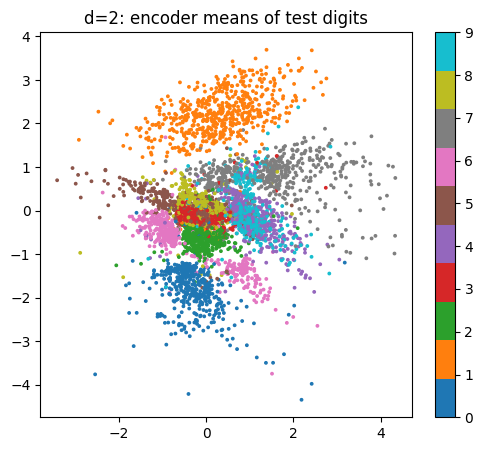

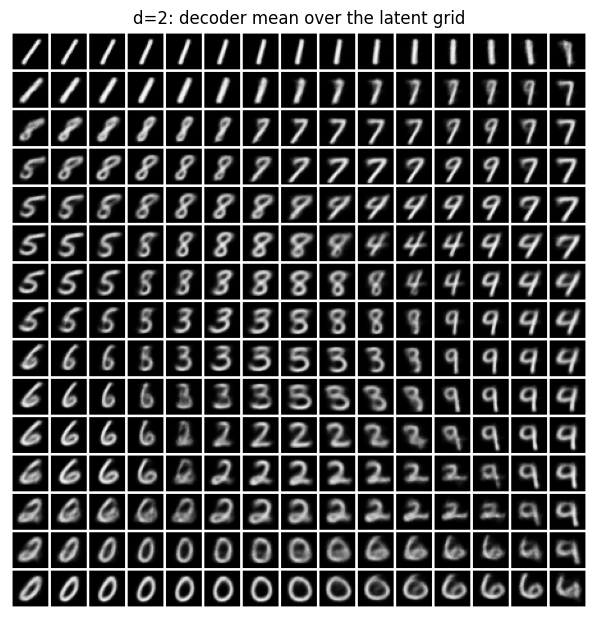

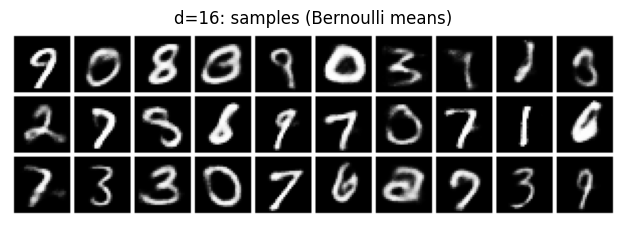

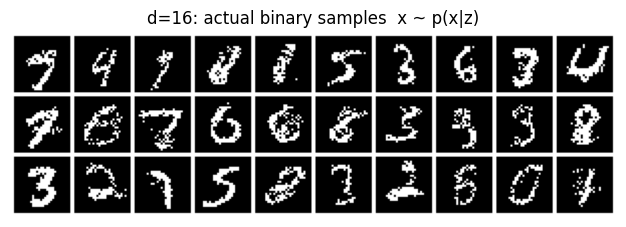

In [ ]:
with torch.no_grad():
    mu = vae_b2.q(x_test_bin[:5000]).mean.cpu()          # .mean of the q distribution = encoder mean
plt.figure(figsize=(6, 5)); plt.scatter(mu[:, 0], mu[:, 1], c=y_test[:5000].cpu(), cmap='tab10', s=3)
plt.colorbar(); plt.title('d=2: encoder means of test digits'); plt.show()

# decode a grid of prior quantiles (Normal(0,1).icdf is another torch.distributions method)
g = Normal(0., 1.).icdf(torch.linspace(0.05, 0.95, 15))
Z = torch.stack(torch.meshgrid(g, g.flip(0), indexing='xy'), -1).view(-1, 2).to(device)
with torch.no_grad():
    show(vae_b2.p_x(Z).mean, nrow=15, scale=0.5, title='d=2: decoder mean over the latent grid')

show(vae_b16.generate(30), title='d=16: samples (Bernoulli means)')
with torch.no_grad():
    show(vae_b16.p_x(torch.randn(30, 16, device=device)).sample(), title='d=16: actual binary samples  x ~ p(x|z)')

Note the last cell: `p_x(z).mean` is the probability image, and `p_x(z).sample()` draws actual binary pixels. The samples are speckled because the pixels are independent given $z$. Papers usually show the means.

## 7. VAE with a Normal decoder (grayscale MNIST)

The decoder outputs the mean $\mu(z)\in[0,1]$, and one scalar σ is learned together with the network. At the optimum, σ is roughly the RMS reconstruction error. Compare this with fixing σ, which is equivalent to MSE with a hand-chosen weight on the KL term.

Log-likelihoods here are *densities* on continuous values, so they are **not comparable** to the Bernoulli numbers above (different data, and a density rather than a probability).

[Normal d=16] epoch  1  train ELBO  -502.27  test ELBO   277.95  KL 42.32  (2.0s/epoch)
[Normal d=16] epoch  2  train ELBO   377.98  test ELBO   484.16  KL 44.42  log p(x) ~   504.06  (2.4s/epoch)
learned sigma = 0.12818549573421478


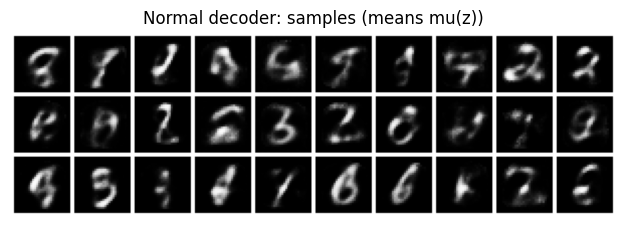

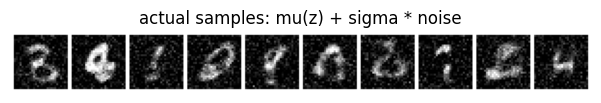

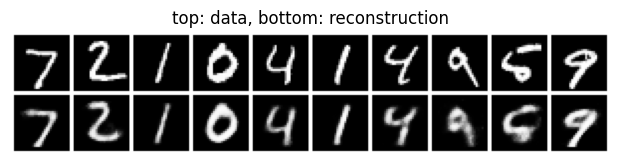

In [ ]:
vae_n16 = train(CVAE(16, 'normal').to(device), x_train, x_test, name='Normal d=16')
print('learned sigma =', vae_n16.log_sigma.exp().item())
show(vae_n16.generate(30), title='Normal decoder: samples (means mu(z))')
with torch.no_grad():
    show(vae_n16.p_x(torch.randn(10, 16, device=device)).sample().clamp(0, 1), title='actual samples: mu(z) + sigma * noise')
    r = vae_n16.p_x(vae_n16.q(x_test[:10]).mean).mean
show(torch.cat([x_test[:10], r]), title='top: data, bottom: reconstruction')

## 8. Conditional VAE: generate a chosen digit

The condition $c$ is the one-hot label. The encoder $q_\phi(z\mid x,c)$ now only needs to encode what the label does **not** already say, i.e. the *style* (slant, thickness, width). The prior $p_\psi(z\mid c)$ is learned.

In the `td` code nothing new is needed: `kl_divergence` between two `Independent(Normal)` objects handles a non-standard prior automatically.

In [ ]:
cvae = train(CVAE(16, 'bernoulli', cond_dim=10).to(device), x_train, x_test_bin, c_train, c_test, name='CVAE d=16')

[CVAE d=16] epoch  1  train ELBO  -160.42  test ELBO  -119.70  KL 11.16  (2.3s/epoch)
[CVAE d=16] epoch  2  train ELBO  -115.67  test ELBO  -106.54  KL 14.07  log p(x) ~  -103.08  (2.3s/epoch)


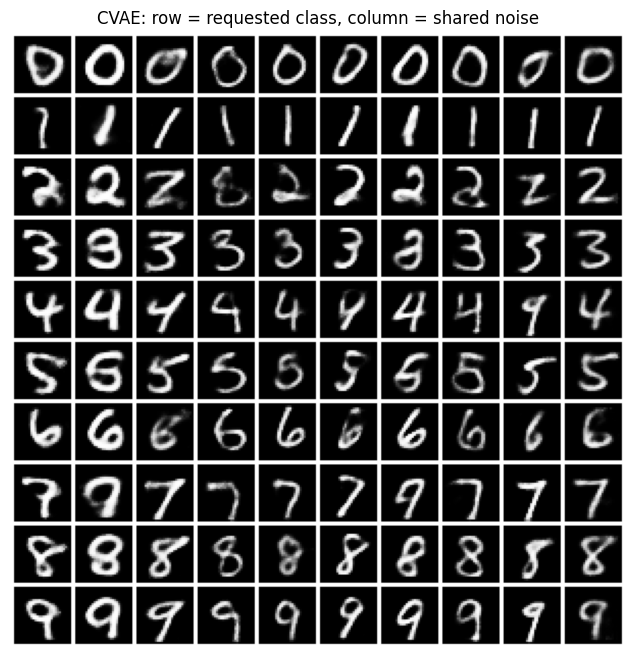

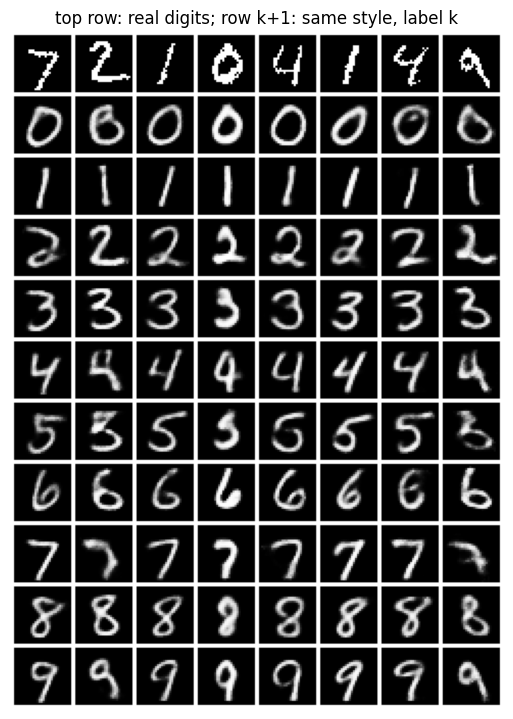

In [ ]:
# rows = classes 0..9; columns share the same noise eps, so each column has a similar "style"
eps = torch.randn(1, 10, 16, device=device).expand(10, 10, 16).reshape(100, 16)
c = F.one_hot(torch.arange(10, device=device).repeat_interleave(10), 10).float()
show(cvae.generate(c=c, eps=eps), title='CVAE: row = requested class, column = shared noise')

# style transfer: encode real digits, then decode their z with every label
with torch.no_grad():
    x0, c0 = x_test_bin[:8], c_test[:8]
    q0 = cvae.q(x0, c0)
    z_style = q0.mean                                       # style codes of 8 real digits
    mu_p, lv_p = cvae.prior_params(c0, z_style)
    eps_style = (z_style - mu_p) / torch.exp(0.5 * lv_p)    # express the style in prior-noise units
rows = [x0]
for k in range(10):
    ck = F.one_hot(torch.full((8,), k, device=device), 10).float()
    rows.append(cvae.generate(c=ck, eps=eps_style))
show(torch.cat(rows), nrow=8, title='top row: real digits; row k+1: same style, label k')

**How much does the label help?** For an exact model,
$$
\log p(x\mid y)-\log p(x)=\log p(y\mid x)-\log p(y)\;\le\;\log 10\approx 2.3\text{ nats},
$$
because $p(y\mid x)\le 1$ and $p(y)=1/10$. The label is worth at most 2.3 nats per image. Compare the $\log p(x\mid c)$ of the CVAE with the $\log p(x)$ of the $d=16$ Bernoulli VAE (same data, same architecture). A gain larger than this bound would signal estimator noise, or a difference in how well the two models were trained.

In [ ]:
r_vae, r_cvae = evaluate(vae_b16, x_test_bin), evaluate(cvae, x_test_bin, c_test)
print(f"VAE  d=16: ELBO {r_vae['elbo']:.2f}   log p(x)   ~ {r_vae['log_px']:.2f}   KL {r_vae['kl']:.2f}")
print(f"CVAE d=16: ELBO {r_cvae['elbo']:.2f}   log p(x|c) ~ {r_cvae['log_px']:.2f}   KL {r_cvae['kl']:.2f}")
print('difference:', round(r_cvae['log_px'] - r_vae['log_px'], 2), 'nats  (exact-model bound: log 10 = 2.30)')

VAE  d=16: ELBO -97.63   log p(x)   ~ -93.01   KL 20.71
CVAE d=16: ELBO -91.78   log p(x|c) ~ -87.13   KL 18.16
difference: 5.88 nats  (exact-model bound: log 10 = 2.30)


Also compare the **KL** terms: the CVAE's is typically smaller, because $z$ no longer has to encode the digit identity.

## 9. CVAE for inpainting: condition on part of the image

Now the condition is itself an image: $c$ = the **top half** of a digit (392 pixels), and $x$ = the **bottom half** (392 pixels, binarized, Bernoulli decoder). This is a *structured prediction* problem. The same top can continue as several different bottoms (the top of a 7 or of a 9, a 3 or a 5, a 4 or a 9), so the conditional distribution $p(x\mid c)$ is **multimodal**.

**Baseline: a plain network.** It predicts $p(x\mid c)=\prod_i \text{Bernoulli}(x_i\mid \ell_i(c))$ directly, with no latent variable. It is trained by exact maximum likelihood, so its log-likelihood is exact, not a bound. Because pixels are independent given $c$, it cannot represent "either a 7 or a 9". The best it can do is predict the **average** bottom, a blurry superposition of all plausible continuations.

**CVAE.** The latent $z\sim p_\psi(z\mid c)$ selects *which* continuation. Given $z$, the pixels can be independent and sharp; the uncertainty lives in $z$. Nothing in the `CVAE` class changes: only `D=392` and `cond_dim=392`. The prior network $p_\psi(z\mid c)$ now sees an image rather than a label.

This mirrors the neural network vs CVAE comparison in the original assignment (which used a Gaussian decoder).

In [ ]:
H = 392                                   # 14 rows x 28 columns
top_train, top_test = x_train[:, :H], x_test[:, :H]           # condition: grayscale top half
bot_test_bin = x_test_bin[:, H:]                              # target: binarized bottom half
bot_train = x_train[:, H:]                                    # binarized on the fly by batch_x

# ---- baseline: deterministic network -> factorized Bernoulli over the bottom half
net = mlp(H, 512, H).to(device)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
for ep in range(EPOCHS):
    perm = torch.randperm(len(bot_train), device=device)
    for i in range(0, len(perm) - 127, 128):
        idx = perm[i:i + 128]
        p_bot = Independent(Bernoulli(logits=net(top_train[idx])), 1)        # batch (128,), event (392,)
        loss = -p_bot.log_prob(torch.bernoulli(bot_train[idx])).mean()
        opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    ll_net = Independent(Bernoulli(logits=net(top_test[:EVAL_N])), 1).log_prob(bot_test_bin[:EVAL_N]).mean().item()
print(f'network: exact log p(bottom | top) = {ll_net:.2f} nats')

# ---- CVAE: identical class, only the sizes change
cvae_inp = train(CVAE(16, 'bernoulli', cond_dim=H, D=H).to(device),
                 bot_train, bot_test_bin, top_train, top_test, name='inpainting CVAE')

network: exact log p(bottom | top) = -62.59 nats
[inpainting CVAE] epoch  1  train ELBO   -77.16  test ELBO   -57.38  KL  4.92  (2.2s/epoch)
[inpainting CVAE] epoch  6  train ELBO   -45.73  test ELBO   -45.15  KL  6.94  (2.3s/epoch)
[inpainting CVAE] epoch 11  train ELBO   -43.45  test ELBO   -43.68  KL  7.29  (2.2s/epoch)
[inpainting CVAE] epoch 16  train ELBO   -42.49  test ELBO   -43.23  KL  7.27  (2.3s/epoch)
[inpainting CVAE] epoch 20  train ELBO   -41.93  test ELBO   -42.66  KL  7.18  log p(x) ~   -40.53  (3.2s/epoch)


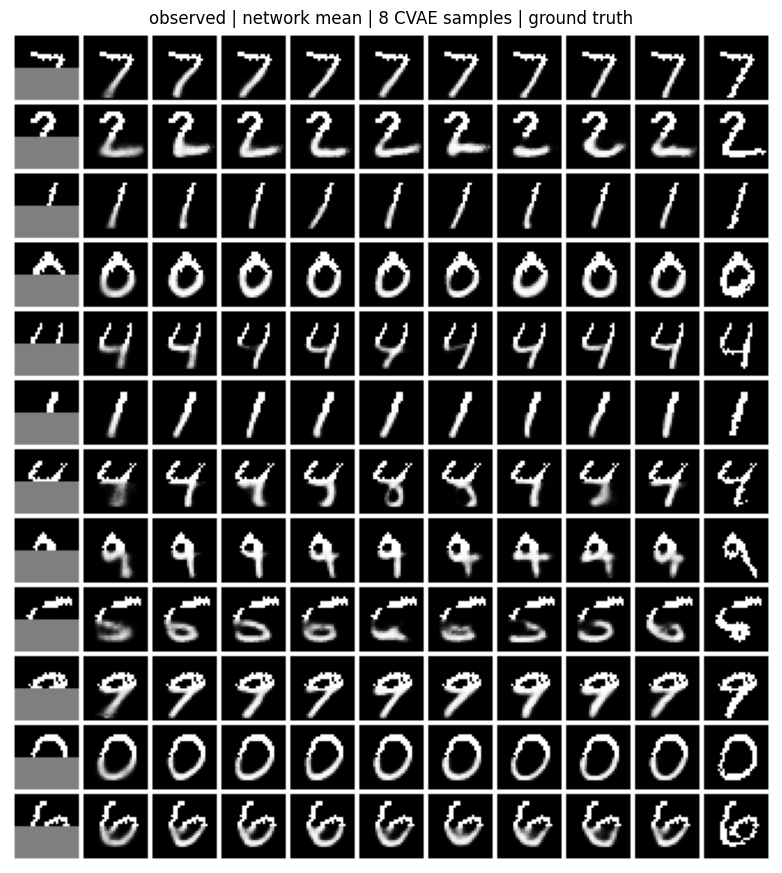

In [ ]:
@torch.no_grad()
def show_inpaintings(idx, n_samples=8):
    top, bot = x_test_bin[idx, :H], x_test_bin[idx, H:]
    cond = top_test[idx]
    gray = torch.full_like(bot, 0.5)
    cols = [torch.cat([top, gray], 1),                                   # what the models see
            torch.cat([top, torch.sigmoid(net(cond))], 1)]               # network: mean prediction
    for _ in range(n_samples):                                           # CVAE: z ~ p(z|c), decoder mean
        cols.append(torch.cat([top, cvae_inp.generate(c=cond)], 1))
    cols.append(torch.cat([top, bot], 1))                                # ground truth
    grid = torch.stack(cols, 1).view(-1, 784)                            # row = one test digit
    show(grid, nrow=len(cols), scale=0.9,
         title='observed | network mean | ' + f'{n_samples} CVAE samples' + ' | ground truth')

show_inpaintings(torch.arange(0, 12, device=device))

**Look for the ambiguous cases.** The cell below picks the test digits on which the CVAE samples *disagree* most, i.e. where $p(x\mid c)$ is most multimodal. On those, the network's prediction is a ghostly blend of two digits, while each CVAE sample commits to one. Some samples may complete a different digit than the ground truth, which is correct behaviour for a model of $p(x\mid c)$.

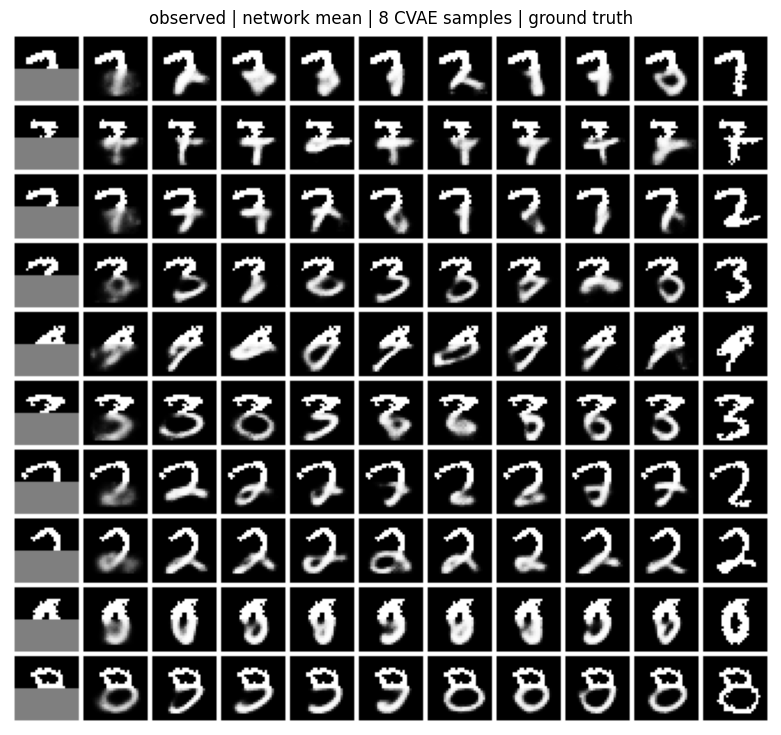

In [ ]:
with torch.no_grad():
    cond = top_test[:1000]
    S = torch.stack([cvae_inp.generate(c=cond) for _ in range(16)])      # (16, 1000, 392)
    spread = S.var(0).sum(-1)                                            # between-sample variability per digit
show_inpaintings(spread.topk(10).indices)

In [ ]:
r_inp = evaluate(cvae_inp, bot_test_bin, top_test)
print(f"network  : log p(bottom | top)   = {ll_net:8.2f}   (exact)")
print(f"CVAE     : log p(bottom | top)  ~= {r_inp['log_px']:8.2f}   (importance-sampled, K={EVAL_K});  ELBO {r_inp['elbo']:.2f},  KL {r_inp['kl']:.2f}")

network  : log p(bottom | top)   =   -62.59   (exact)
CVAE     : log p(bottom | top)  ~=   -40.53   (importance-sampled, K=500);  ELBO -42.76,  KL 7.18


**Discussion.**
* Do the two models solve the same problem? Both model $p(x\mid c)$. The network's family can only represent *unimodal, factorized* conditionals, while the CVAE's is a continuous mixture of factorized ones. The network gives the best single *average* prediction; the CVAE gives *samples*.
* The likelihood numbers need care. The network's is exact, whereas the CVAE's is an estimate from below. If they are close, the gain from $z$ shows up mainly in sample quality on ambiguous digits, not in the average log-likelihood.
* When is a CVAE overkill? When $p(x\mid c)$ is essentially unimodal: low noise, or $c$ determines $x$. Then a deterministic predictor is simpler and just as good.
* Try `latent_dim=2` versus `16`. How does the diversity of the samples change?

## 10. Cheat sheet: by hand ↔ `torch.distributions`

| quantity | by hand | `torch.distributions` |
|---|---|---|
| encoder | `mu, logvar = enc(x)` | `q = Independent(Normal(mu, (0.5*logvar).exp()), 1)` |
| reparameterized sample | `mu + exp(0.5*logvar) * randn` | `q.rsample()` / `q.rsample((K,))` |
| $\log q(z\mid x)$ | `log_normal(z, mu, logvar)` | `q.log_prob(z)` |
| Bernoulli decoder | `(x*l - softplus(l)).sum(-1)` | `Independent(Bernoulli(logits=l), 1).log_prob(x)` |
| Normal decoder | `log_normal(x, m, 2*log_sigma)` | `Independent(Normal(m, sigma), 1).log_prob(x)` |
| KL to a (conditional) prior | `kl_normal(mu_q, lv_q, mu_p, lv_p)` | `kl_divergence(q, p)` |
| IW estimate | `log_mean_exp(log_w, 0)` | `torch.logsumexp(log_w, 0) - log K` |
| decoder mean / sample | `sigmoid(l)` / `torch.bernoulli(...)` | `p_x.mean` / `p_x.sample()` |

**When to use which.** Writing things by hand once is the best way to understand the ELBO. Afterwards, `torch.distributions` removes shape and stability bugs and lets you swap distributions (e.g. `ContinuousBernoulli`, `MixtureSameFamily`, flows through `TransformedDistribution`) without rewriting the loss. Its main traps are forgetting `Independent`, and using `sample()` where you needed `rsample()`.

**Exercises.**
1. Condition the inpainting CVAE on the *left* half instead of the top half, or on a random mask (pass the mask as part of $c$).
2. Replace the learned prior in the CVAE with $\mathcal N(0, I)$. Does style transfer get better or worse?
3. Fix σ of the Normal decoder at 1.0 and at 0.05 and compare the KL and the samples. Explain the result with $\beta = 2\sigma^2$.